# RFM Customer Segmentation using K-Means (Online Retail II)

**Objective:** Segment customers of a UK online gift retailer using Recency, Frequency and Monetary (RFM) features, and find which segments drive the most revenue.

**Dataset:** UCI Online Retail II (transactions from 01-Dec-2009 to 09-Dec-2011, ~1.07 million rows, 8 columns).

**Approach:**
1. Load and understand the data
2. Exploratory Data Analysis (EDA)
3. Data cleaning
4. RFM feature creation and transformation
5. Choosing K (Elbow + Silhouette)
6. Final K-Means model, stability check and comparison with Hierarchical clustering
7. Segment naming, revenue contribution and cluster visualisation
8. Business recommendations, conclusion and limitations

## 1. Load Data

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/online_retail_II.csv")
df['Invoice'] = df['Invoice'].astype(str)
df['StockCode'] = df['StockCode'].astype(str)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Data Understanding

In [14]:
print(df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())
df.info()

2009-12-01 07:45:00 to 2011-12-09 12:50:00
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [15]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print("Customers:", df['Customer ID'].nunique())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Duplicates: 34335
Customers: 5942


In [16]:
print("Negative quantity:", (df['Quantity'] < 0).sum())
print("Price <= 0:", (df['Price'] <= 0).sum())
print(df['Country'].value_counts().head())

Negative quantity: 22950
Price <= 0: 6207
Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Name: count, dtype: int64


**Observations**
- The data has 1,067,371 rows and 8 columns, covering about two years (Dec 2009 to Dec 2011).
- Customer ID is missing in 243,007 rows (about 22.8%). Without Customer ID we cannot build customer-level RFM, so these rows will be removed.
- There are 34,335 duplicate rows, 22,950 rows with negative quantity (returns/adjustments) and 6,207 rows with Price <= 0.
- The United Kingdom dominates the data (about 92% of rows).

## 3. Exploratory Data Analysis (EDA)

In [17]:
# 1. Percentage of rows with missing Customer ID
print("Missing Customer ID %:", round(df['Customer ID'].isnull().mean() * 100, 2))

# 2. Cancelled invoices (Invoice number starts with 'C')
print("Cancelled invoice rows:", df['Invoice'].str.startswith('C').sum())

# 3. Negative quantity rows that are NOT cancelled invoices
neg_not_cancel = (df['Quantity'] < 0) & (~df['Invoice'].str.startswith('C'))
print("Negative quantity but not cancelled:", neg_not_cancel.sum())

# 4. Country share in percentage
print("\nCountry share (%):")
print((df['Country'].value_counts(normalize=True) * 100).round(2).head())

# 5. StockCodes that are not normal products (do not start with 5 digits)
print("\nNon-product StockCodes (top 10):")
print(df.loc[~df['StockCode'].str.match(r'^\d{5}'), 'StockCode'].value_counts().head(10))

Missing Customer ID %: 22.77
Cancelled invoice rows: 19494
Negative quantity but not cancelled: 3457

Country share (%):
Country
United Kingdom    91.94
EIRE               1.67
Germany            1.65
France             1.34
Netherlands        0.48
Name: proportion, dtype: float64

Non-product StockCodes (top 10):
StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
Name: count, dtype: int64


**Observations**
- 19,494 rows are cancelled invoices (Invoice starts with 'C'). Another 3,457 rows have negative quantity without a cancellation; these look like manual adjustments.
- Some StockCodes are not products (POST, DOT, M, BANK CHARGES, ADJUST, AMAZONFEE etc.). These are postage, fees and adjustments, so they should not be treated as customer purchases.

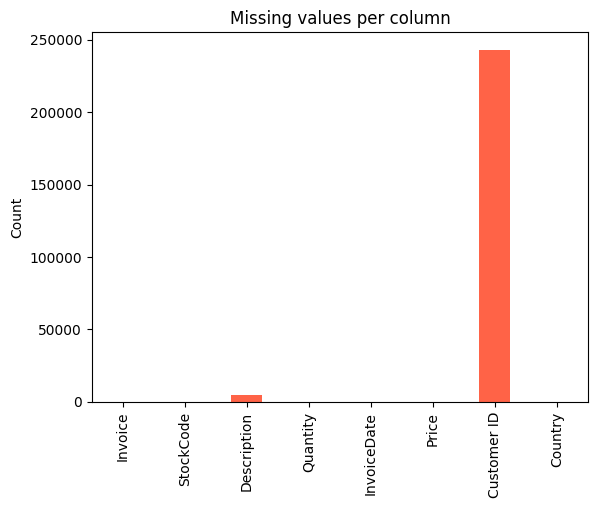

In [18]:
df.isnull().sum().plot(kind='bar', color='tomato')
plt.title("Missing values per column")
plt.ylabel("Count")
plt.show()

Customer ID is the only column with a large number of missing values. Description has a small number of missing values, which does not matter for RFM.

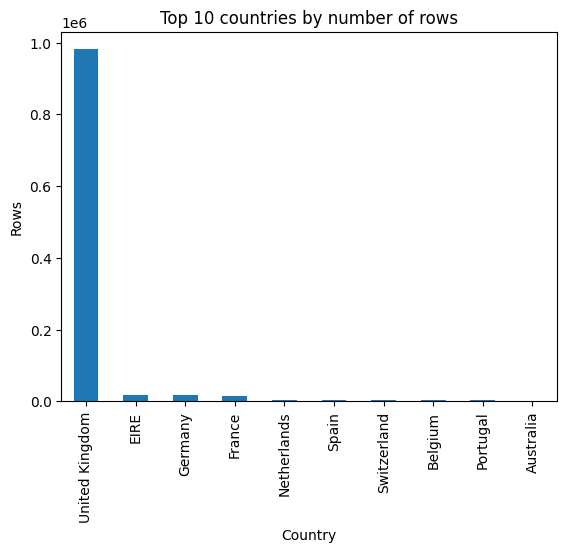

In [19]:
df['Country'].value_counts().head(10).plot(kind='bar')
plt.title("Top 10 countries by number of rows")
plt.ylabel("Rows")
plt.show()

The United Kingdom is by far the biggest market; all other countries are very small in comparison.

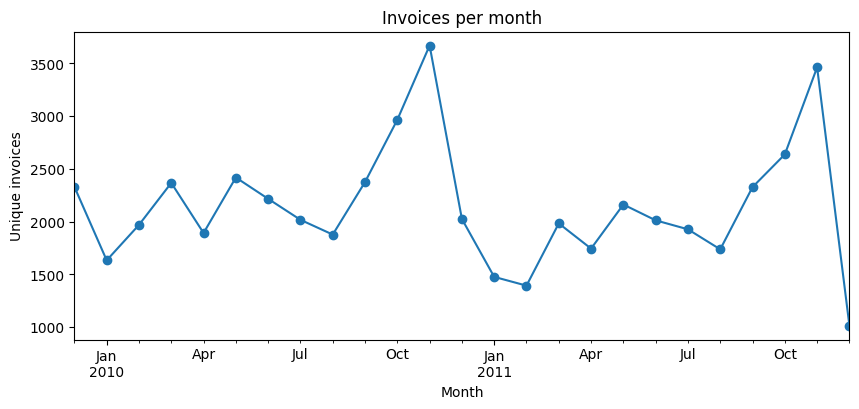

In [20]:
df['Month'] = df['InvoiceDate'].dt.to_period('M')
df.groupby('Month')['Invoice'].nunique().plot(marker='o', figsize=(10, 4))
plt.title("Invoices per month")
plt.ylabel("Unique invoices")
plt.show()

Invoices peak in October to November of both years (festive season demand). The last point (December 2011) is low only because the data stops on 9 December, so that month is incomplete.

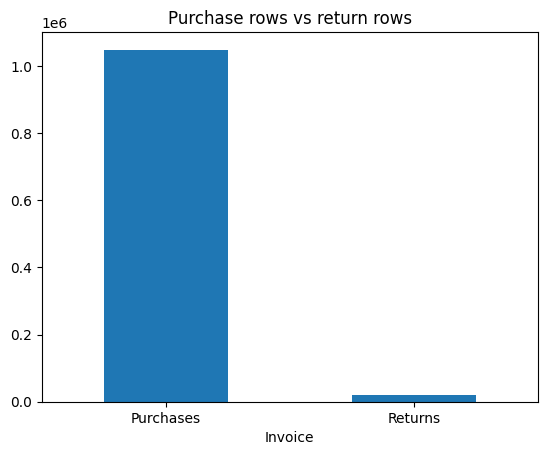

In [21]:
is_return = df['Invoice'].str.startswith('C')
is_return.value_counts().rename({False: 'Purchases', True: 'Returns'}).plot(kind='bar')
plt.title("Purchase rows vs return rows")
plt.xticks(rotation=0)
plt.show()

Returns are a very small share of all rows compared to purchases.

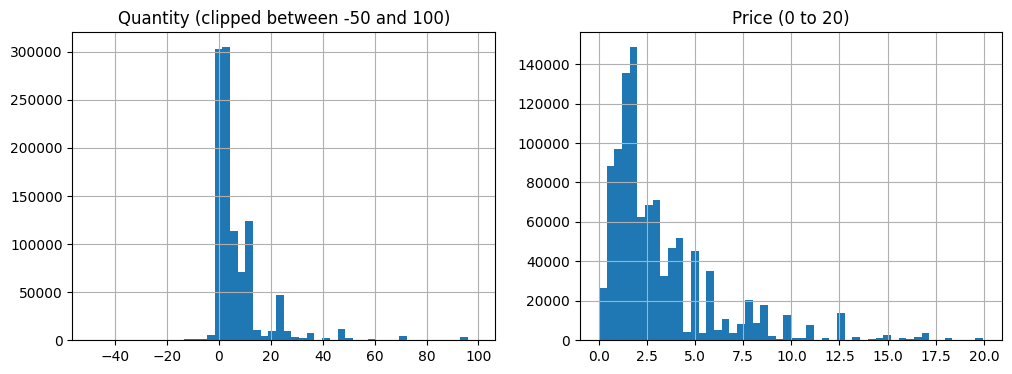

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df[(df['Quantity'] > -50) & (df['Quantity'] < 100)]['Quantity'].hist(bins=50, ax=ax[0])
ax[0].set_title("Quantity (clipped between -50 and 100)")

df[(df['Price'] > 0) & (df['Price'] < 20)]['Price'].hist(bins=50, ax=ax[1])
ax[1].set_title("Price (0 to 20)")

plt.show()

Most orders have small quantities and most products are priced below 5. Both distributions are right-skewed, so a few very large orders can dominate the totals later.

## 4. Data Cleaning and Preprocessing

In [23]:
print("Start:", df.shape)

# 1. Remove rows with missing Customer ID
df = df.dropna(subset=['Customer ID'])
print("After removing missing Customer ID:", df.shape)

# 2. Remove duplicate rows
df = df.drop_duplicates()
print("After removing duplicates:", df.shape)

# 3. Keep only real products (StockCode starts with 5 digits)
df = df[df['StockCode'].str.match(r'^\d{5}')]
print("After keeping only product StockCodes:", df.shape)

# 4. Remove rows with Price <= 0
df = df[df['Price'] > 0].copy()
print("After removing Price <= 0:", df.shape)

# 5. Convert Customer ID to integer
df['Customer ID'] = df['Customer ID'].astype(int)

Start: (1067371, 9)
After removing missing Customer ID: (824364, 9)
After removing duplicates: (797885, 9)
After keeping only product StockCodes: (794223, 9)
After removing Price <= 0: (794163, 9)


**Cleaning summary**
- Started with 1,067,371 rows and ended with 794,163 rows (about 74% retained).
- Rows without Customer ID were removed because RFM needs a customer identity.
- Duplicates, non-product StockCodes (postage, fees, adjustments) and rows with Price <= 0 were removed.
- Cancelled invoices (returns) were intentionally kept, because they reduce the net spend of a customer.

## 5. RFM Feature Creation
- **Recency:** days since the customer's last purchase (reference date = one day after the last purchase in the data)
- **Frequency:** number of unique purchase invoices
- **Monetary:** net spend (purchases minus returns)

In [24]:
# Total amount per row (returns will be negative automatically)
df['Total'] = df['Quantity'] * df['Price']

# Purchases only (not cancelled, quantity positive)
purchases = df[(~df['Invoice'].str.startswith('C')) & (df['Quantity'] > 0)]

# Reference date = one day after the last purchase in data
reference_date = purchases['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

# Recency and Frequency from purchases only
rfm = purchases.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('Invoice', 'nunique')
)

# Monetary = purchases + returns (net spend)
rfm['Monetary'] = df.groupby('Customer ID')['Total'].sum()

rfm = rfm.reset_index()
print(rfm.shape)
rfm.head()

Reference date: 2011-12-10 12:50:00
(5852, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,326,3,169.36
1,12347,2,8,4921.53
2,12348,75,5,1658.40
3,12349,19,3,3654.54
4,12350,310,1,294.40


In [25]:
# Remove customers whose net spend is zero or negative (returned more than they bought)
rfm['Monetary'] = rfm['Monetary'].round(2)
print("Customers with Monetary <= 0:", (rfm['Monetary'] <= 0).sum())

rfm = rfm[rfm['Monetary'] > 0].copy()
print(rfm.shape)
rfm[['Recency', 'Frequency', 'Monetary']].describe()

Customers with Monetary <= 0: 20
(5832, 4)


,Recency,Frequency,Monetary
count,5832.000000,5832.000000,5832.000000
mean,199.849623,6.271091,2805.481847
std,208.366013,12.767477,13847.905914
min,1.000000,1.000000,2.900000
25%,25.000000,1.000000,333.792500
50%,95.000000,3.000000,843.740000
75%,379.000000,7.000000,2179.890000
max,738.000000,373.000000,578408.640000


**Observations**
- 5,852 customers had at least one purchase. After removing customers with zero or negative net spend, **5,832 customers** remain for clustering.
- Recency is the number of days since last purchase, so a smaller value means a more recent customer.
- Monetary has a very large maximum compared to its median, which shows strong right skew (a few very big customers).

## 6. RFM Distribution and Transformation

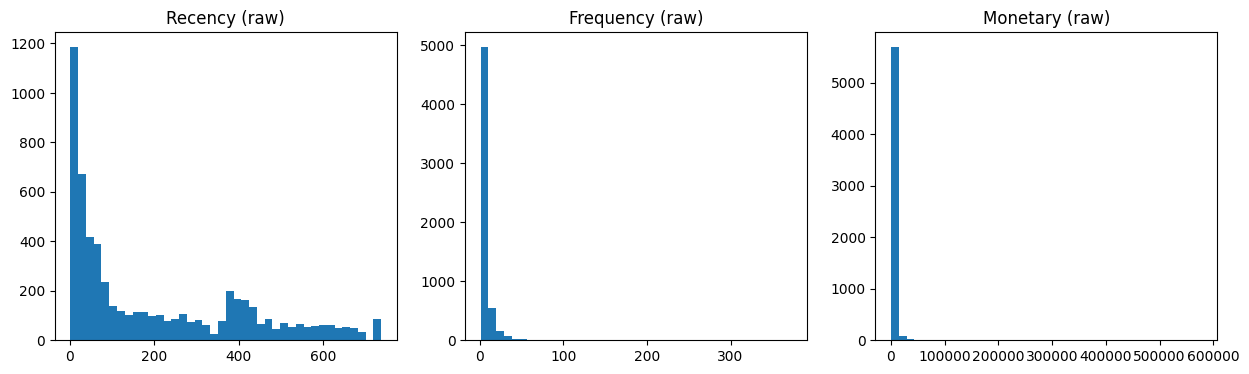

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    ax[i].hist(rfm[col], bins=40)
    ax[i].set_title(col + " (raw)")
plt.show()

In [27]:
from scipy.stats import skew

for col in ['Recency', 'Frequency', 'Monetary']:
    print(col, "skewness:", round(skew(rfm[col]), 2))

print(rfm[['Recency', 'Frequency', 'Monetary']].corr().round(2))

Recency skewness: 0.9
Frequency skewness: 12.02
Monetary skewness: 26.77
           Recency  Frequency  Monetary
Recency       1.00      -0.26     -0.12
Frequency    -0.26       1.00      0.62
Monetary     -0.12       0.62      1.00


**Observations**
- Frequency (skew about 12) and Monetary (skew about 27) are extremely right-skewed. K-Means uses distance, so a few huge values would dominate the clusters.
- Recency is only mildly skewed (about 0.9).
- Frequency and Monetary are positively correlated (about 0.62), which is expected: customers who buy more often also spend more.

In [28]:
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].copy()

for col in ['Recency', 'Frequency', 'Monetary']:
    rfm_log[col] = np.log(rfm[col])
    print(col, "skew before:", round(skew(rfm[col]), 2),
          "| after log:", round(skew(rfm_log[col]), 2))

Recency skew before: 0.9 | after log: -0.61
Frequency skew before: 12.02 | after log: 0.61
Monetary skew before: 26.77 | after log: 0.23


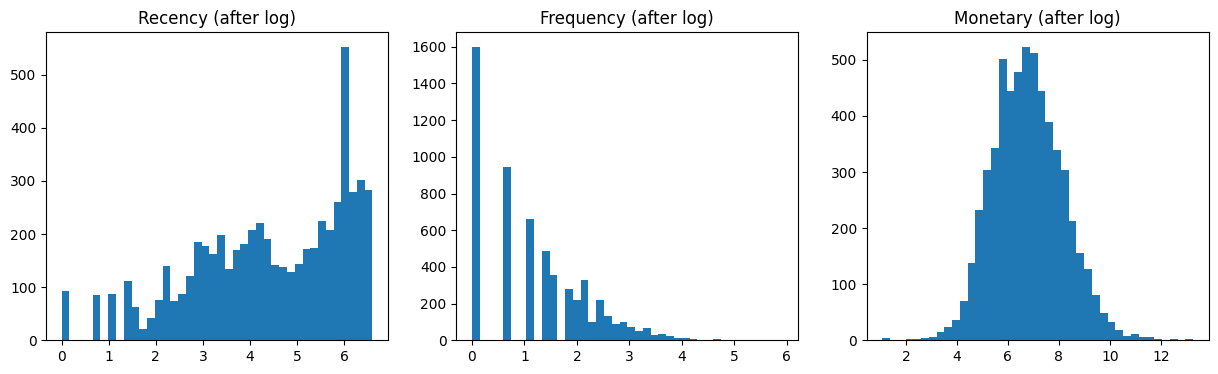

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    ax[i].hist(rfm_log[col], bins=40)
    ax[i].set_title(col + " (after log)")
plt.show()

**Decision on transformation**
- Log transform brings Frequency (12.02 to 0.61) and Monetary (26.77 to 0.23) close to symmetric, so log is applied to these two.
- For Recency the log transform makes skew go from 0.9 to -0.61 (it just flips the skew to the other side), so **Recency is kept raw**.
- After this, all three features are standardised with StandardScaler so that each has mean 0 and standard deviation 1.

In [30]:
from sklearn.preprocessing import StandardScaler

rfm_t = pd.DataFrame()
rfm_t['Recency'] = rfm['Recency']                  # raw
rfm_t['Frequency'] = np.log(rfm['Frequency'])      # log
rfm_t['Monetary'] = np.log(rfm['Monetary'])        # log

scaler = StandardScaler()
X = scaler.fit_transform(rfm_t)

print(pd.DataFrame(X, columns=rfm_t.columns).describe().round(2))

       Recency  Frequency  Monetary
count  5832.00    5832.00   5832.00
mean      0.00      -0.00     -0.00
std       1.00       1.00      1.00
min      -0.95      -1.17     -4.15
25%      -0.84      -1.17     -0.71
50%      -0.50      -0.10     -0.03
75%       0.86       0.72      0.65
max       2.58       4.60      4.70


## 7. Choosing K (Elbow + Silhouette)

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
sil = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, labels))
    print(k, round(km.inertia_, 1), round(sil[-1], 3))

2 8641.8 0.425
3 5725.6 0.393
4 4482.6 0.356
5 3598.6 0.367
6 3069.4 0.35
7 2737.6 0.338
8 2493.0 0.315
9 2308.2 0.31
10 2168.4 0.315


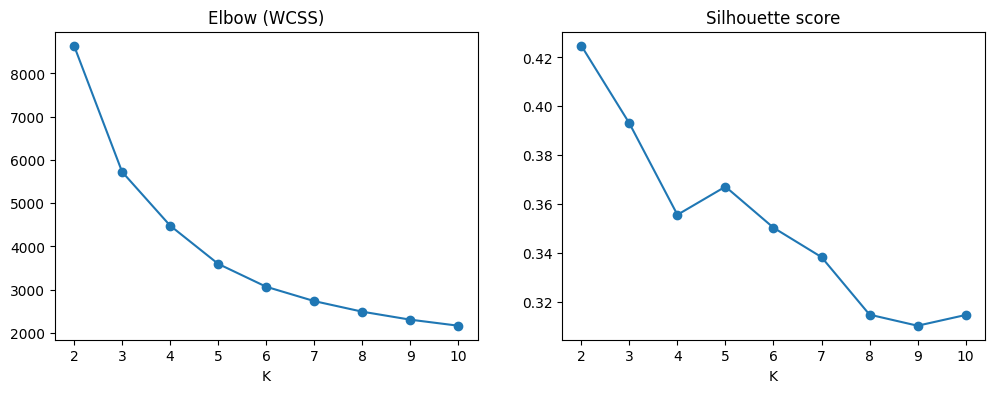

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(range(2, 11), wcss, marker='o')
ax[0].set_title("Elbow (WCSS)")
ax[0].set_xlabel("K")

ax[1].plot(range(2, 11), sil, marker='o')
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("K")

plt.show()

**Observations**
- The elbow curve bends around K = 3 to 4 and there is no sharp single elbow.
- Silhouette is highest for K = 2 (0.425), but only two groups (active vs inactive) are too coarse to be useful for marketing.
- K = 3 and K = 4 are compared below, and the K = 4 solution is chosen because it separates the high-value group (Champions) from regular customers, which is the most business-meaningful split..

In [33]:
for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    rfm['Cluster'] = km.fit_predict(X)
    print("K =", k)
    print(rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].median().round(1))
    print(rfm['Cluster'].value_counts().sort_index())
    print()

K = 3
         Recency  Frequency  Monetary
Cluster                              
0           28.0       10.0    3378.4
1          437.0        1.0     320.0
2           61.0        2.0     640.8
Cluster
0    1870
1    1795
2    2167
Name: count, dtype: int64

K = 4
         Recency  Frequency  Monetary
Cluster                              
0          466.0        1.0     321.8
1           19.0       14.0    5447.5
2           60.0        5.0    1347.0
3           75.0        1.0     329.4
Cluster
0    1557
1    1087
2    1927
3    1261
Name: count, dtype: int64



**K = 3 vs K = 4**
- With K = 3, there is a single high-frequency cluster (median Frequency 10), which hides the difference between top customers (Frequency 14, Monetary about 5,448) and regular customers (Frequency 5, Monetary about 1,347) that K = 4 reveals.
- With K = 4, the clusters are clearly different: a high-value frequent group (median Frequency 14, Monetary about 5,448), a regular group, recent one-time buyers (Recency about 75) and lost one-time buyers (Recency about 466).

**Final choice: K = 4**

In [34]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm['Cluster'] = km.fit_predict(X)

profile = rfm.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Med_Recency=('Recency', 'median'),
    Med_Frequency=('Frequency', 'median'),
    Med_Monetary=('Monetary', 'median'),
    Mean_Monetary=('Monetary', 'mean')
).round(1)

profile['Share_%'] = (profile['Customers'] / len(rfm) * 100).round(1)
print(profile)

         Customers  Med_Recency  Med_Frequency  Med_Monetary  Mean_Monetary  \
Cluster                                                                       
0             1557        466.0            1.0         321.8          494.7   
1             1087         19.0           14.0        5447.5        11092.9   
2             1927         60.0            5.0        1347.0         1586.5   
3             1261         75.0            1.0         329.4          377.6   

         Share_%  
Cluster           
0           26.7  
1           18.6  
2           33.0  
3           21.6  


## 9. Model Validation

### 9.1 Stability check (different random seeds)
Adjusted Rand Index (ARI) compares two clusterings; 1.0 means identical.

In [35]:
from sklearn.metrics import adjusted_rand_score

base = rfm['Cluster']
for seed in [1, 7, 21, 99]:
    other = KMeans(n_clusters=4, n_init=10, random_state=seed).fit_predict(X)
    print(seed, round(adjusted_rand_score(base, other), 3))

1 0.99
7 0.994
21 0.984
99 0.995


ARI is between 0.98 and 0.995 for all seeds, so the K-Means result is **very stable** and does not depend on random initialisation.

### 9.2 Comparison with Hierarchical clustering (Ward linkage)

In [36]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=4, linkage='ward')
rfm['HC_Cluster'] = hc.fit_predict(X)

print("Silhouette K-Means     :", round(silhouette_score(X, rfm['Cluster']), 3))
print("Silhouette Hierarchical:", round(silhouette_score(X, rfm['HC_Cluster']), 3))
print("ARI (K-Means vs Hierarchical):",
      round(adjusted_rand_score(rfm['Cluster'], rfm['HC_Cluster']), 3))

Silhouette K-Means     : 0.356
Silhouette Hierarchical: 0.319
ARI (K-Means vs Hierarchical): 0.518


In [37]:
print(rfm.groupby('HC_Cluster')[['Recency', 'Frequency', 'Monetary']].median().round(1))
print(rfm['HC_Cluster'].value_counts().sort_index())
print()
print(pd.crosstab(rfm['Cluster'], rfm['HC_Cluster']))

            Recency  Frequency  Monetary
HC_Cluster                              
0             438.0        1.0     359.7
1              27.0       10.0    3539.2
2              50.5        3.0     868.6
3              87.0        1.0     221.6
HC_Cluster
0    1797
1    1767
2    1474
3     794
Name: count, dtype: int64

HC_Cluster     0     1     2    3
Cluster                          
0           1518     0     8   31
1             15  1072     0    0
2            173   695  1055    4
3             91     0   411  759


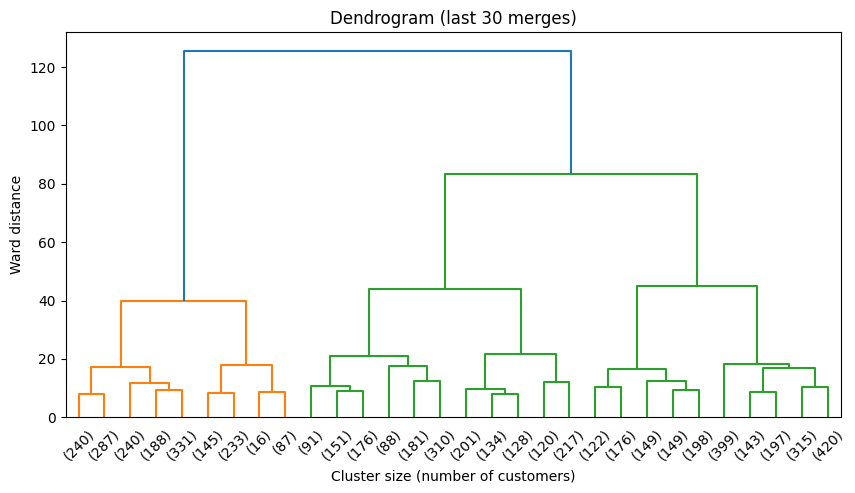

In [38]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title("Dendrogram (last 30 merges)")
plt.xlabel("Cluster size (number of customers)")
plt.ylabel("Ward distance")
plt.show()

**Observations**
- K-Means has a higher silhouette score (about 0.356) than Hierarchical clustering (about 0.319), so K-Means gives slightly better separated clusters.
- The ARI between the two methods is only about 0.52, so they agree on the main structure but not fully. The crosstab shows that the Champions group (Cluster 1) and the "lost" group (Cluster 0) are recovered almost exactly by hierarchical clustering, while the boundary between Regular customers and Champions is softer.
- The dendrogram shows one big split at the top and no very clear cut below it. This means the customers form more of a continuum than sharply separated islands, so the segments should be read as practical groups for marketing, not as natural, perfectly separated clusters.

## 10. Customer Segmentation and Business Insights
Segment names are assigned automatically from the cluster profiles (so they do not depend on cluster numbers):
- **Champions:** highest median Monetary
- **Lost one-time buyers:** highest median Recency
- **Regular customers:** the higher-Frequency one among the remaining two
- **Recent one-time buyers:** the remaining cluster

In [39]:
med = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].median()

champ = med['Monetary'].idxmax()
lost = med['Recency'].idxmax()
rest = [c for c in med.index if c not in (champ, lost)]
regular = med.loc[rest, 'Frequency'].idxmax()
recent = [c for c in rest if c != regular][0]

names = {
    champ: 'Champions',
    regular: 'Regular customers',
    recent: 'Recent one-time buyers',
    lost: 'Lost one-time buyers'
}
print(names)

rfm['Segment'] = rfm['Cluster'].map(names)
rfm['Segment'].value_counts()

{np.int32(1): 'Champions', np.int32(2): 'Regular customers', 3: 'Recent one-time buyers', np.int32(0): 'Lost one-time buyers'}


,count
Segment,
Regular customers,1927
Lost one-time buyers,1557
Recent one-time buyers,1261
Champions,1087


## 11. How Much Revenue Each Segment Generates

In [40]:
rev = rfm.groupby('Segment')['Monetary'].sum()
share = pd.DataFrame({
    'Customers_%': (rfm['Segment'].value_counts(normalize=True) * 100).round(1),
    'Revenue_%': (rev / rev.sum() * 100).round(1)
})
print(share)

                        Customers_%  Revenue_%
Segment                                       
Champions                      18.6       73.7
Lost one-time buyers           26.7        4.7
Recent one-time buyers         21.6        2.9
Regular customers              33.0       18.7


**Key insight**
- **Champions are only about 18.6% of customers but generate about 73.7% of net revenue.**
- Regular customers (33.0% of customers) generate about 18.7% of revenue.
- Recent one-time buyers (21.6%) and Lost one-time buyers (26.7%) together are almost half of the customers but generate only about 7.6% of revenue.

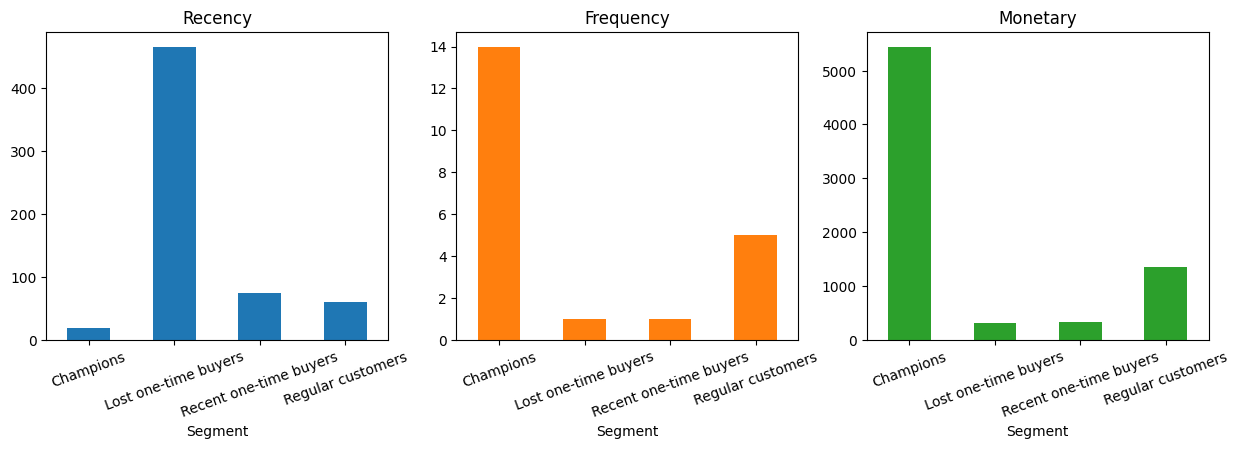

In [41]:
prof = rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].median()
prof.plot(kind='bar', subplots=True, layout=(1, 3), figsize=(15, 4), legend=False, rot=20)
plt.show()

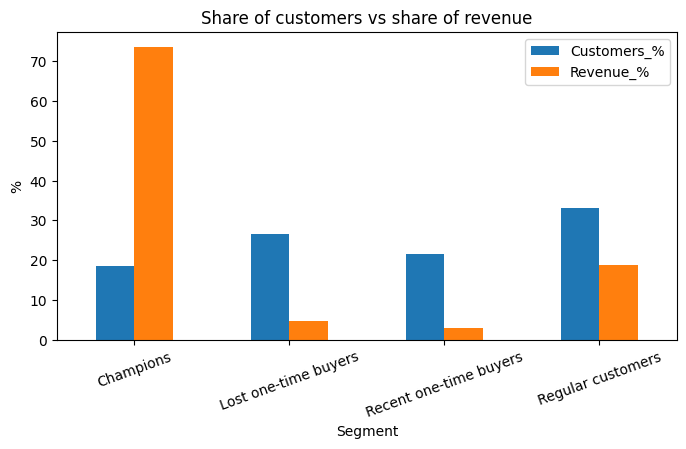

In [42]:
share.plot(kind='bar', figsize=(8, 4), rot=20)
plt.title("Share of customers vs share of revenue")
plt.ylabel("%")
plt.show()

The bar chart clearly shows the revenue concentration: the Champions bar for revenue is much taller than their customer share, while it is the opposite for both one-time buyer groups.

## 12. Cluster Visualisation (PCA, 2D)
The three RFM features are projected to two principal components just to visualise the segments.

Variance explained by 2 components: 0.951


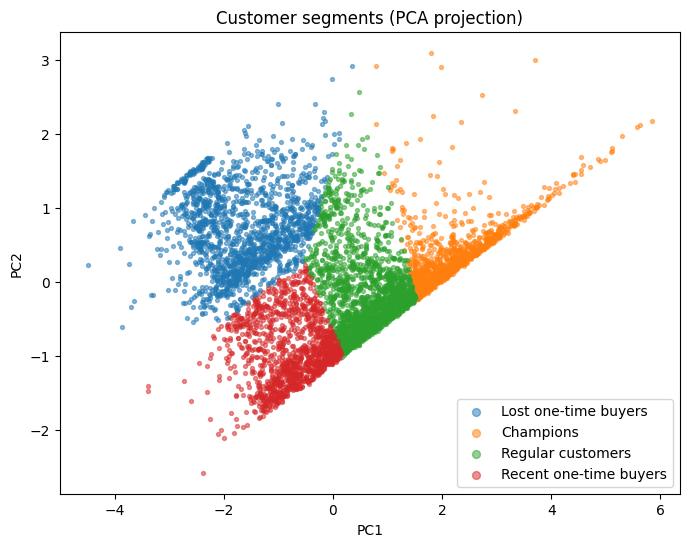

In [43]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
print("Variance explained by 2 components:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
for seg in rfm['Segment'].unique():
    mask = (rfm['Segment'] == seg).values
    plt.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.5, label=seg)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Customer segments (PCA projection)")
plt.legend(markerscale=2)
plt.show()

The PCA plot shows that Champions and Lost one-time buyers sit at opposite ends, while Regular customers and Recent one-time buyers lie in between and touch their neighbours. This matches the validation result: the segments form a continuum with soft boundaries.

## 13. Business Recommendations

| Segment | Profile (median) | Suggested action |
|---|---|---|
| Champions | Recency about 19 days, Frequency 14, Monetary about 5,448 | Protect them: loyalty rewards, early access to new products, dedicated account support |
| Regular customers | Recency about 60 days, Frequency 5, Monetary about 1,347 | Grow them: cross-sell and bundle offers to move them towards Champions |
| Recent one-time buyers | Recency about 75 days, Frequency 1, Monetary about 329 | Convert them: welcome series and a second-purchase discount soon after the first order |
| Lost one-time buyers | Recency about 466 days, Frequency 1, Monetary about 322 | Win-back: low-cost reactivation campaign only, since their value is low |

## 14. Conclusion
- Customers were segmented into four groups using log-transformed and standardised RFM features with K-Means (K = 4).
- Results are stable across random seeds (ARI above 0.98).
- A small group of Champions (18.6% of customers) drives about 74% of revenue, so retention of this group is the top business priority.

## 15. Limitations
- Silhouette is weak-to-moderate (about 0.36) and hierarchical clustering agrees only partly (ARI about 0.52), so segments have soft boundaries.
- Only RFM features were used; product category, country and discount data could improve the segmentation.
- Customers without Customer ID (about 23% of rows) were excluded.
- The data covers only two years and one retailer, so results may not generalise to other businesses.